# Label-noise ablation

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from finsler_learning.shepplogan_pipeline.aggregate_shepplogan_results import (
    METHODS,
    collect_quality,
    collect_setup_metrics,
    merge_combined_table,
    label_noise_latex_table,
)

sns.set_context("notebook")
plt.rcParams["figure.figsize"] = (10, 6)


/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11_label_noise")
runs = sorted(base_path.glob("label_noise_*"), key=lambda path: float(path.name.split("_")[-1]))
setup_paths = {
    float(run.name.split("_")[-1]): run
    for run in runs
}


## Interpolation

In [3]:
df_inter, df_extra = collect_setup_metrics(
    setup_paths,
    methods=METHODS,
    setup_column="Label Noise",
)
df_quality_inter, df_quality_extra = collect_quality(
    setup_paths,
    methods=METHODS,
    setup_column="Label Noise",
)
df_inter.head()


,Geodesic Distance,Kendall Tau,Base Metric,Label Noise
0,4.412794,1.0,Euclidean,0.0
1,4.202264,1.0,Euclidean,0.0
2,6.120747,1.0,Euclidean,0.0
3,3.672450,1.0,Euclidean,0.0
4,8.126889,1.0,Euclidean,0.0


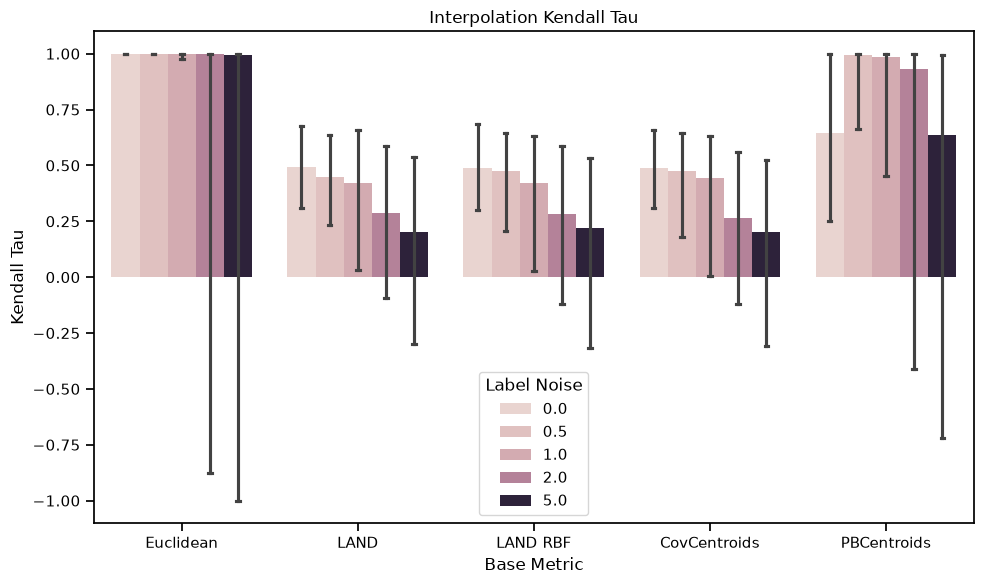

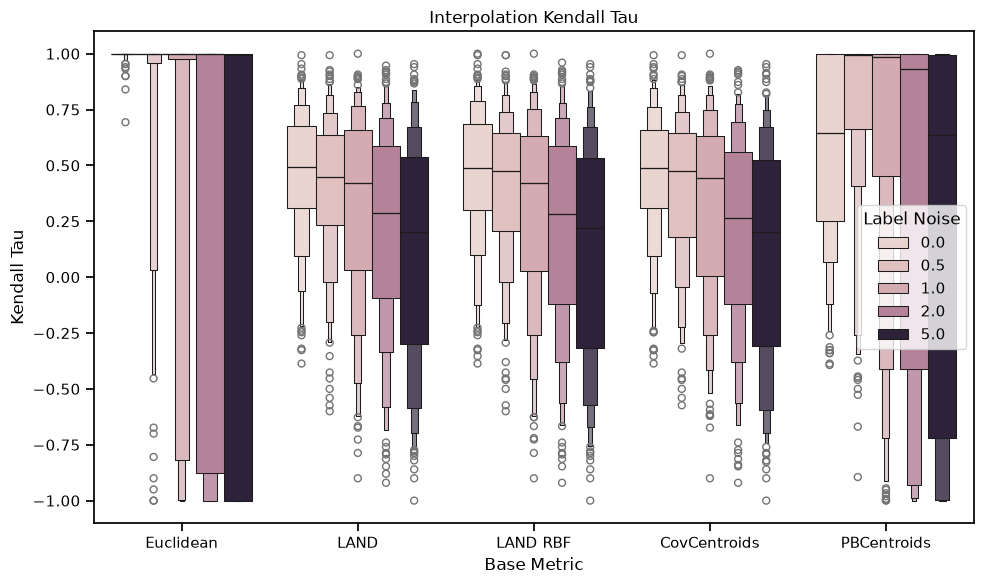

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_inter, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Label Noise", estimator="median", ax=ax, errorbar=("pi", 50), capsize=0.1)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxenplot(data=df_inter, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Label Noise", ax=ax)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()


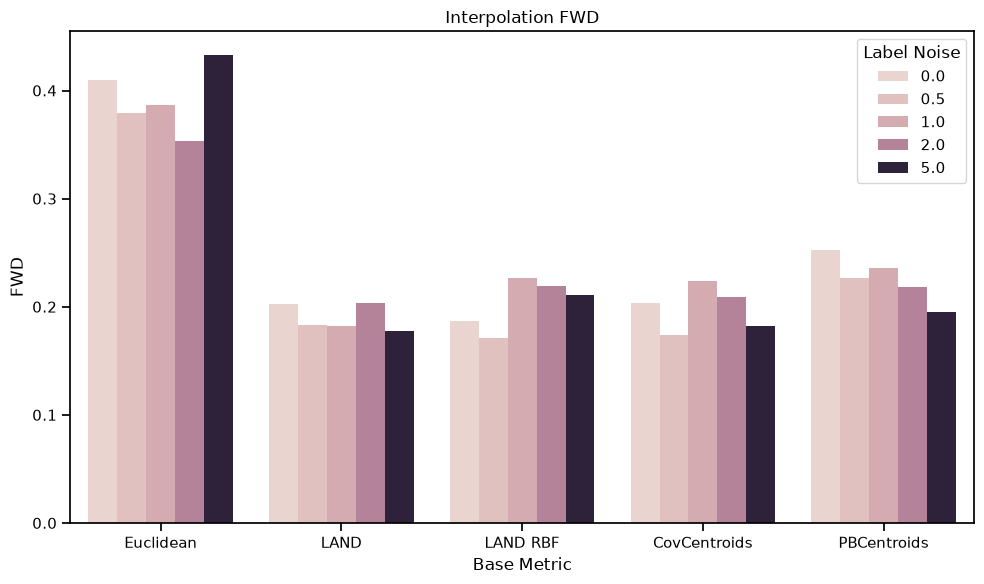

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_quality_inter, x="Base Metric", order=[name for name, _ in METHODS], y="FWD", hue="Label Noise", ax=ax, errorbar=None)
ax.set_title("Interpolation FWD")
plt.tight_layout()
plt.show()


## Extrapolation

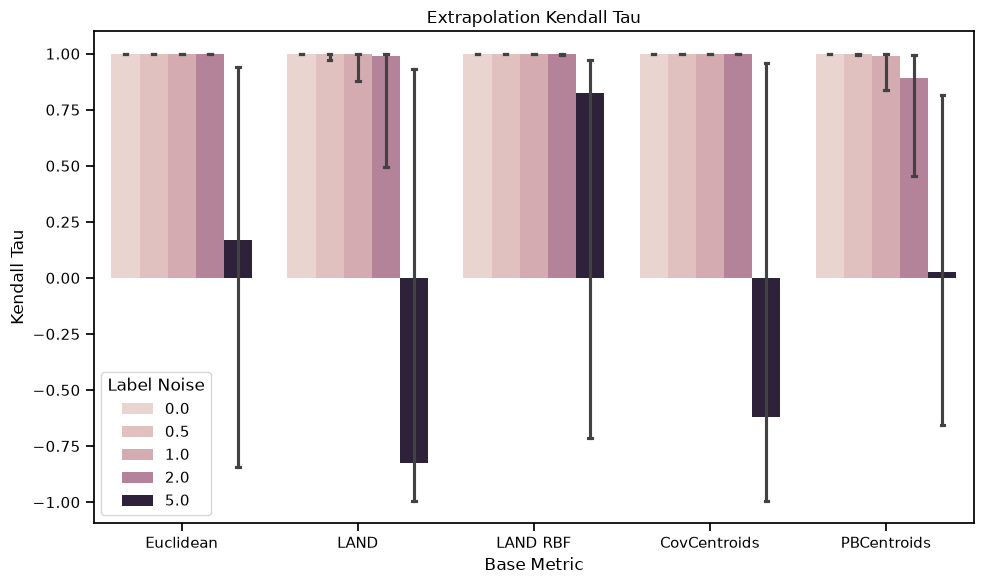

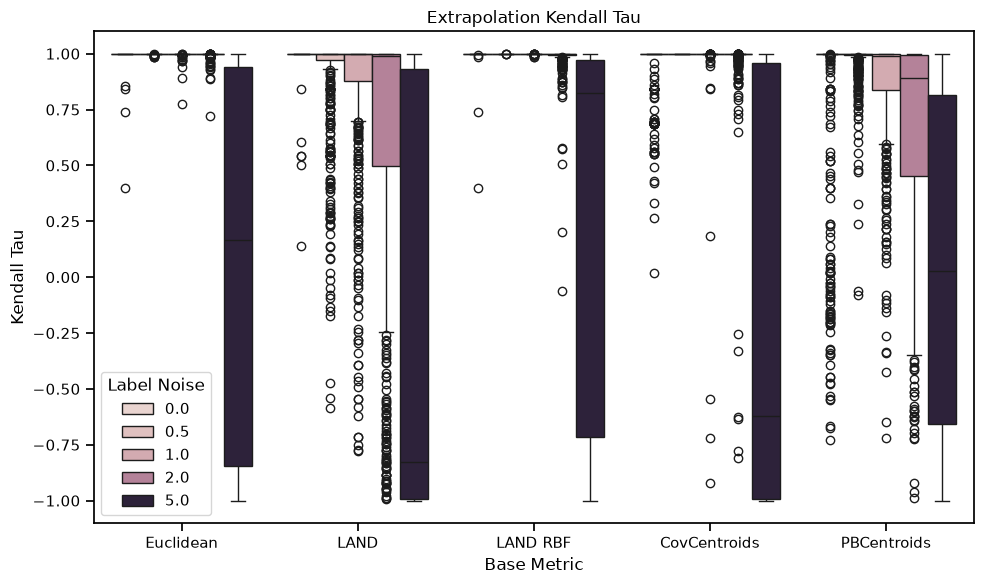

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Label Noise", estimator="median", ax=ax, errorbar=("pi", 50), capsize=0.1)
ax.set_title("Extrapolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Kendall Tau", hue="Label Noise", ax=ax)
ax.set_title("Extrapolation Kendall Tau")
plt.tight_layout()
plt.show()


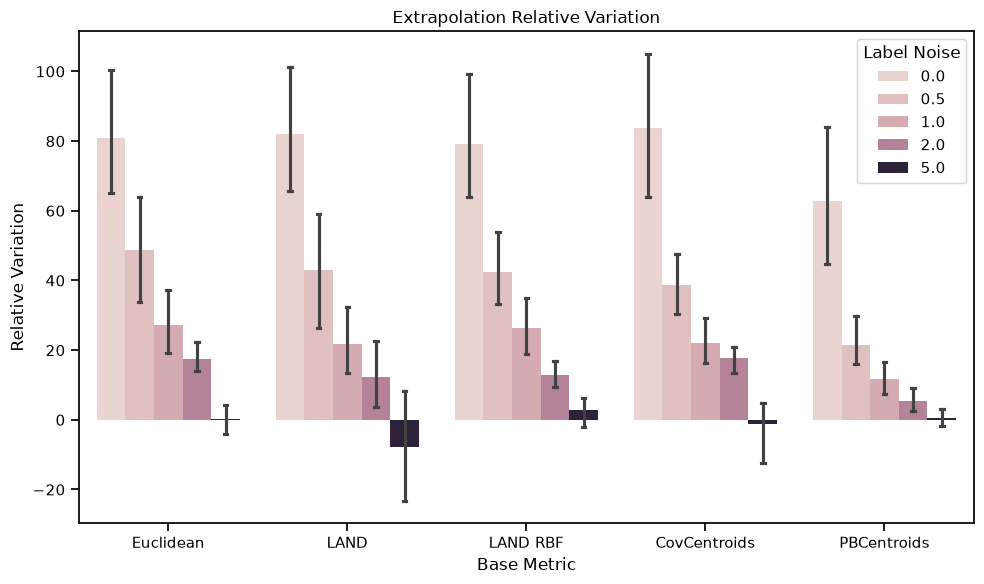

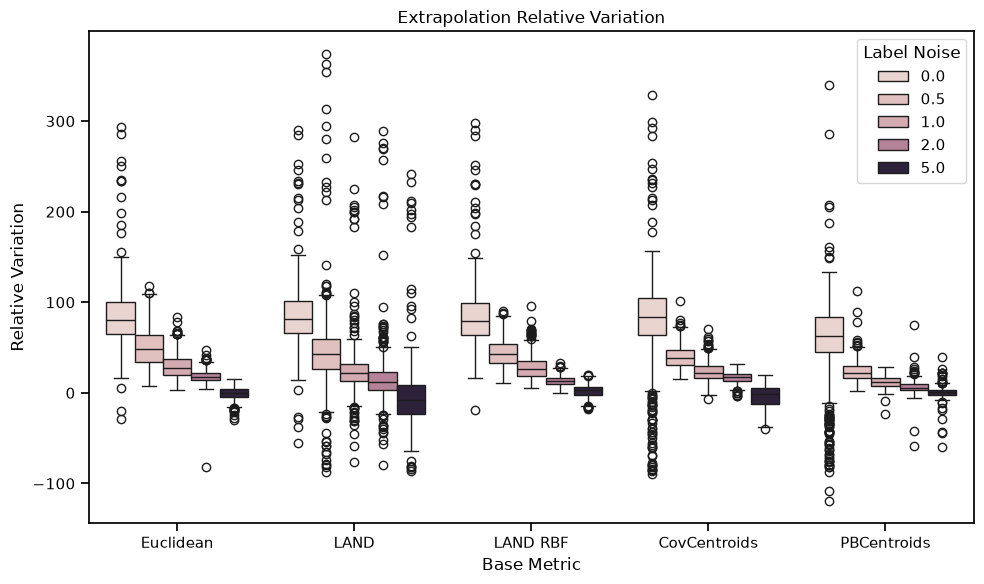

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Relative Variation", hue="Label Noise", estimator="median", ax=ax, errorbar=("pi", 50), capsize=0.1)
ax.set_title("Extrapolation Relative Variation")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxplot(data=df_extra, x="Base Metric", order=[name for name, _ in METHODS], y="Relative Variation", hue="Label Noise", ax=ax)
ax.set_title("Extrapolation Relative Variation")
plt.tight_layout()
plt.show()


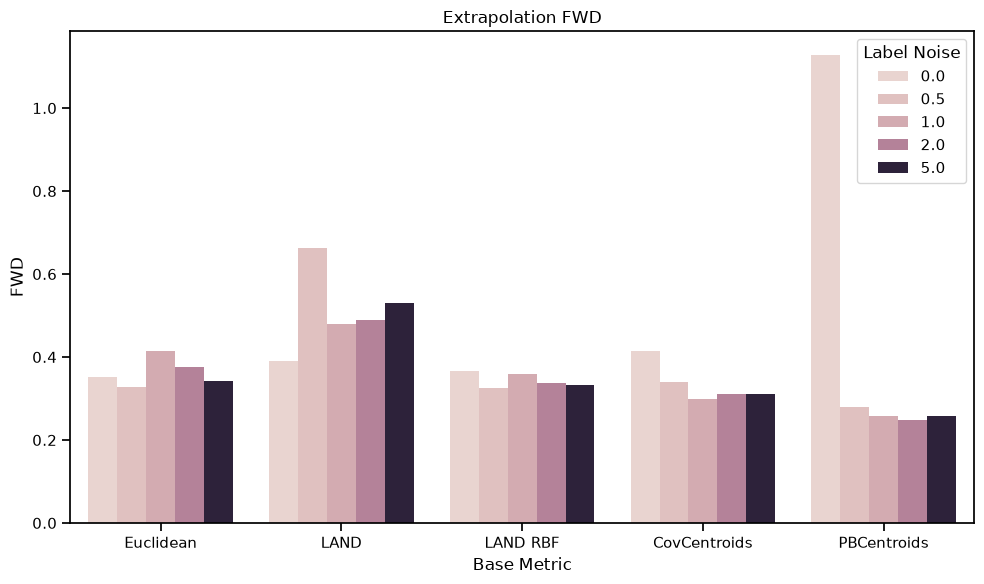

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(data=df_quality_extra, x="Base Metric", order=[name for name, _ in METHODS], y="FWD", hue="Label Noise", ax=ax, errorbar=None)
ax.set_title("Extrapolation FWD")
plt.tight_layout()
plt.show()


## Combined results

In [9]:
combined = merge_combined_table(
    df_inter,
    df_extra,
    df_quality_inter,
    df_quality_extra,
    setup_column="Label Noise",
)
combined


,Base Metric,Label Noise,Kendall Tau Median Inter,Kendall Tau IQR Inter,Kendall Tau Median Extra,Kendall Tau IQR Extra,Relative Variation Median Extra,Relative Variation IQR Extra,FWD Inter,FWD Extra
0,CovCentroids,0.0,0.486667,"(0.30999999999999994, 0.6599999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",83.840446,"(63.840091705322266, 105.08301544189453)",0.203050,0.415531
1,CovCentroids,0.5,0.476667,"(0.18166666666666664, 0.6449999999999999)",1.000000,"(0.9999999999999998, 0.9999999999999998)",38.596413,"(30.298081874847412, 47.662269592285156)",0.173711,0.339980
2,CovCentroids,1.0,0.443333,"(0.006666666666666665, 0.6333333333333332)",1.000000,"(0.9999999999999998, 0.9999999999999998)",22.067335,"(16.18047523498535, 29.32809352874756)",0.223878,0.298973
3,CovCentroids,2.0,0.266667,"(-0.11833333333333332, 0.5583333333333331)",1.000000,"(0.9999999999999998, 0.9999999999999998)",17.699200,"(13.454247951507568, 20.919687271118164)",0.209313,0.310255
4,CovCentroids,5.0,0.200000,"(-0.30999999999999994, 0.5233333333333332)",-0.621995,"(-0.9933333333333332, 0.9603715441494948)",-1.249906,"(-12.396981954574585, 4.877156853675842)",0.182063,0.310434
5,Euclidean,0.0,1.000000,"(0.9999999999999998, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",80.795265,"(65.02141189575195, 100.50840950012207)",0.409939,0.352272
6,Euclidean,0.5,1.000000,"(0.9999999999999998, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",48.851624,"(33.750715255737305, 63.886094093322754)",0.379153,0.327644
7,Euclidean,1.0,1.000000,"(0.9749999999999998, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",27.150028,"(19.2874116897583, 37.39163875579834)",0.386802,0.414853
8,Euclidean,2.0,1.000000,"(-0.8766666666666665, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",17.387901,"(14.094187259674072, 22.46191644668579)",0.353066,0.376242
9,Euclidean,5.0,0.992494,"(-0.9999999999999998, 0.9999999999999998)",0.168464,"(-0.8452234760920178, 0.94)",0.327672,"(-4.0903379917144775, 4.139335751533508)",0.433083,0.342298


In [10]:
caption = (
    r"Label-noise ablation on the Shepp-Logan dataset. "
    r"Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. "
    r"Values are reported as median [IQR]."
)
latex = label_noise_latex_table(
    combined,
    caption=caption,
    label="tab:label_noise_shepplogan",
    method_order=METHODS,
)
print(latex)


\begin{table}[ht]
\centering
\caption{Label-noise ablation on the Shepp-Logan dataset. Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$. Values are reported as median [IQR].}
\label{tab:label_noise_shepplogan}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
    & & \multicolumn{2}{c}{Interpolation} & \multicolumn{3}{c}{Extrapolation} \\
    \cmidrule(lr){3-4} \cmidrule(lr){5-7}
    Base metric & Label noise
      & Kendall Tau ($\uparrow$) & FWD ($\downarrow$)
      & Kendall Tau ($\uparrow$) & Relative Variation (\%) & FWD ($\downarrow$) \\
\midrule
    \multirow{5}{*}{Euclidean} & 0.0 & $1.00\,[1.00, 1.00]$ & $0.41$ & $1.00\,[1.00, 1.00]$ & $80.80\,[65.02, 100.51]$ & $0.35$ \\
     & 0.5 & $1.00\,[1.00, 1.00]$ & $0.38$ & $1.00\,[1.00, 1.00]$ & $48.85\,[33.75, 63.89]$ & $0.33$ \\
     & 1.0 & $1.00\,[0.97, 1.00]$ & $0.39$ & $1.00\,[1.00, 1.00]$ & $27.15\,[19.29, 37.39]$ & $0.41$ \\
     & 2.0 & $1.00\,[-0.88, 1.00]$ & $0.35$ & $1.00\,[1.00, 1.00]$ & $17.39\,[14.09, 